# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.


## Setup de Bibliotecas e Dados

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [2]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("harshadapatil31/student-performance-and-study-habits-dataset")

df = pd.read_csv(os.path.join(path, 'student_performance_dataset.csv'))

df.head()



c:\Users\Bibi\AVD-20262-pratica-streamlit\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 14.7k/14.7k [00:00<00:00, 7.51MB/s]

Extracting files...


,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


In [3]:
# REMOÇÃO DE COLUNAS DE IDENTIFICAÇÃO E REAJUSTE DE VARIÁVEIS

if "student_id" in df.columns:
    df = df.set_index("student_id")
    print("✓ Coluna 'student_id' definida como índice do DataFrame.")

VARS_QUANT = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
VARS_CAT = df.select_dtypes(include=["object", "category"]).columns.tolist()

print(f"Variáveis Quantitativas ({len(VARS_QUANT)}): {VARS_QUANT}")
print(f"Variáveis Categóricas ({len(VARS_CAT)}): {VARS_CAT}")

✓ Coluna 'student_id' definida como índice do DataFrame.
Variáveis Quantitativas (5): ['study_time_hours', 'attendance_percent', 'sleep_hours', 'previous_grade', 'final_exam_score']
Variáveis Categóricas (6): ['gender', 'parental_education', 'internet_access', 'extracurricular_activities', 'part_time_job', 'final_grade']


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

O dataset Student Performance and Study Habits possui diversas variáveis sobre a rotina acadêmica e de vida dos estudantes (como horas diárias de estudo, frequência de revisão, hábitos de sono, frequência às aulas e métodos de estudo) junto com os resultados de desempenho (como a nota final). Quantas linhas vocês esperam que um dataset com pesquisas sobre hábitos de estudantes como esse tenha — centenas ou milhares de alunos?

### Dimensão e Tipos de Dados

In [4]:
df.shape

(1000, 11)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000 entries, 1 to 1000
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   gender                      1000 non-null   object 
 1   study_time_hours            1000 non-null   float64
 2   attendance_percent          1000 non-null   float64
 3   sleep_hours                 1000 non-null   float64
 4   parental_education          898 non-null    object 
 5   internet_access             1000 non-null   object 
 6   extracurricular_activities  1000 non-null   object 
 7   part_time_job               1000 non-null   object 
 8   previous_grade              1000 non-null   float64
 9   final_exam_score            1000 non-null   float64
 10  final_grade                 1000 non-null   object 
dtypes: float64(5), object(6)
memory usage: 93.8+ KB


In [6]:
df.describe()

,study_time_hours,attendance_percent,sleep_hours,previous_grade,final_exam_score
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,3.570700,85.092300,6.799500,69.740900,83.543500
std,1.478559,9.270685,1.203527,12.613425,10.341333
min,0.500000,54.800000,3.200000,31.300000,46.800000
25%,2.600000,78.800000,5.900000,61.000000,76.075000
50%,3.600000,85.200000,6.800000,69.600000,83.800000
75%,4.500000,91.900000,7.600000,78.400000,91.525000
max,8.100000,100.000000,10.000000,100.000000,100.000000


### Duplicadas

In [7]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

Categorizando o desempenho acadêmico para facilitar a interpretação

O dataset original traz a nota final do exame (Exam_Score) em uma escala numérica contínua. Para facilitar a visualização e permitir comparações entre grupos ao longo da análise, vamos criar uma nova variável binária chamada status_aprovacao (onde notas acima ou iguais a 60 indicam "Aprovado" e abaixo de 60 indicam "Reprovado").

In [8]:
import numpy as np

df["status_aprovacao"] = np.where(df["final_exam_score"] >= 60, "Aprovado", "Reprovado")

print(df["status_aprovacao"].value_counts())

df.head()

status_aprovacao
Aprovado     988
Reprovado     12
Name: count, dtype: int64


,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade,status_aprovacao
student_id,,,,,,,,,,,,
1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A,Aprovado
2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A,Aprovado
3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A,Aprovado
4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B,Aprovado
5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D,Aprovado


## 2. Dados Faltantes

In [9]:
df.isna().sum()

gender                          0
study_time_hours                0
attendance_percent              0
sleep_hours                     0
parental_education            102
internet_access                 0
extracurricular_activities      0
part_time_job                   0
previous_grade                  0
final_exam_score                0
final_grade                     0
status_aprovacao                0
dtype: int64

**Discussao:** Alguma feature tem dados ausentes nos seus dados?
Sim estão faltando 102 dados de 1000 na feature parental_education.

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos uma feature 'parental_education' com dados ausentes.

Pela fonte de dados observamos que:

* parental_education - “Maior nível de escolaridade dos pais”

*Como os dados foram coletados:*
- O método de coleta dos dados não é informado de forma detalhada na página do dataset no Kaggle. Não são especificados o local, o período ou o procedimento utilizado para obter as informações dos estudantes. Dessa forma, não é possível afirmar se os dados foram coletados por meio de questionários, registros acadêmicos ou outra metodologia. O dataset foi disponibilizado no Kaggle para fins de análise, contendo informações relacionadas ao desempenho acadêmico e aos hábitos de estudo dos estudantes.

*Qual a natureza da fonte de dados:*
- Considerando que os dados estão relacionados a estudantes, podem existir limitações decorrentes da forma como essas informações foram obtidas e registradas. Além disso, como o dataset disponibilizado no Kaggle não apresenta detalhes sobre o local, período ou método utilizado para a coleta, não é possível determinar com precisão a representatividade dos estudantes presentes na amostra. Também podem existir dados faltantes ou possíveis inconsistências que influenciem a análise dos hábitos de estudo e do desempenho acadêmico.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [10]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['parental_education']
parental_education    102
dtype: int64


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

In [11]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()

if len(cols_com_ausentes) >= 2:
    tabela_contingencia = pd.crosstab(
        df[cols_com_ausentes[0]].isna(),
        df[cols_com_ausentes[1]].isna(),
        rownames=[f"{cols_com_ausentes[0]} ausente"],
        colnames=[f"{cols_com_ausentes[1]} ausente"],
    )

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title("As ausências ocorrem juntas?")
    plt.tight_layout()
    plt.show()
else:
    print(
        f"Não há colunas suficientes com dados ausentes para cruzar. Colunas encontradas: {cols_com_ausentes}"
    )

Não há colunas suficientes com dados ausentes para cruzar. Colunas encontradas: ['parental_education']


### Pra discutir: Análise do Mecanismo de Ausência de Dados

* **Quantas linhas têm as duas colunas ausentes ao mesmo tempo?**
  * **0 linhas.** Como a coluna `parental_education` é a única que apresenta valores nulos em todo o dataset, é impossível haver ocorrência simultânea de ausências entre duas colunas.

* **Impacto na hipótese do mecanismo de ausência:**
  * A hipótese de dependência direta entre ausências de variáveis distintas (ausências conjuntas) fica automaticamente **descartada**, pois a omissão ocorre de forma isolada na variável `parental_education`.

* **Avaliação do Mecanismo (MCAR / MAR / MNAR):**
  * **MCAR (Missing Completely at Random):** É a hipótese mais provável caso a falta de registro da escolaridade dos pais seja um erro casual no formulário/sistema de coleta, sem nenhuma relação com o desempenho do estudante (`final_exam_score`), número de horas de estudo ou outras características socioeconômicas.
  * **MAR (Missing at Random):** Ocorre se a probabilidade de a informação estar ausente for explicada por outra variável do dataset (por exemplo, estudantes de determinada faixa de tempo de estudo ou escola responderem menos a essa pergunta).
  * **MNAR (Missing Not at Random):** Ocorre se a ausência depender da própria característica omitida (por exemplo, quando pais com menor nível de instrução evitam declarar a escolaridade por hesitação ou estigma).

* **Conclusão para o tratamento:**
  * Por ser uma ausência isolada em uma única coluna, o padrão deve ser investigado verificando se as médias ou distribuições das demais variáveis (ex: notas do exame final) variam significativamente entre o grupo que informou e o grupo que não informou a escolaridade dos pais.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes na variável `parental_education` ou eventuais outliers), vamos calcular as estatísticas descritivas e analisar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção.

Por exemplo, a assimetria e a presença de outliers nas variáveis numéricas (como `final_exam_score` ou horas de estudo) definem se a imputação e a padronização devem ser feitas com base na **média e desvio padrão** ou na **mediana e intervalo interquartil (IQR)**. Da mesma forma, na variável categórica `parental_education`, a distribuição das frequências ajudará a decidir entre a imputação pela **moda** ou a criação de uma categoria específica para dados ausentes (ex: `"Não informado"`).

In [12]:
VARS_QUANT = ["study_time_hours", "attendance_percent", "sleep_hours", "previous_grade", "final_exam_score"]
VARS_QUALI = ["gender", "parental_education", "internet_access", "extracurricular_activities", "part_time_job","final_grade"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
study_time_hours,3.57,3.60,1.48,0.50,8.10,0.12,-0.34
attendance_percent,85.09,85.20,9.27,54.80,100.00,-0.34,-0.26
sleep_hours,6.80,6.80,1.20,3.20,10.00,-0.02,-0.22
previous_grade,69.74,69.60,12.61,31.30,100.00,0.00,-0.24
final_exam_score,83.54,83.80,10.34,46.80,100.00,-0.22,-0.51


### Pra discutir: Análise de Assimetria e Curtose das Variáveis

* **Identificação de Assimetria e Cauda Pesada:**
  * **Nenhuma das variáveis** apresenta assimetria acentuada (`skewness` > 1 ou < -1) nem curtose elevada em módulo (`kurtosis` > 2).
  * Os valores de **skewness** variam entre **-0.34** e **0.12**, enquanto a **kurtosis** varia entre **-0.51** e **-0.22**. Isso indica distribuições relativamente simétricas e sem caudas especialmente pesadas.
  * Essas medidas descritivas não são suficientes para afirmar normalidade. O teste de Shapiro-Wilk e o QQ-Plot serão usados como evidências complementares.

* **Coerência com o Contexto Educacional:**
  * O comportamento é compatível com o contexto educacional: horas de estudo, horas de sono, frequência e notas possuem limites práticos e metodológicos que restringem valores extremos.
  * `sleep_hours` e `study_time_hours` possuem limites relacionados à rotina diária, enquanto `attendance_percent`, `previous_grade` e `final_exam_score` estão em escalas com limite superior de 100.


### Distribuições de dados

Primeiro observamos as distribuições das variáveis quantitativas na base completa. Em seguida, onde fizer sentido, comparamos os alunos Aprovados e Reprovados. Como há apenas 12 estudantes reprovados, as comparações por classe devem ser interpretadas com cautela.


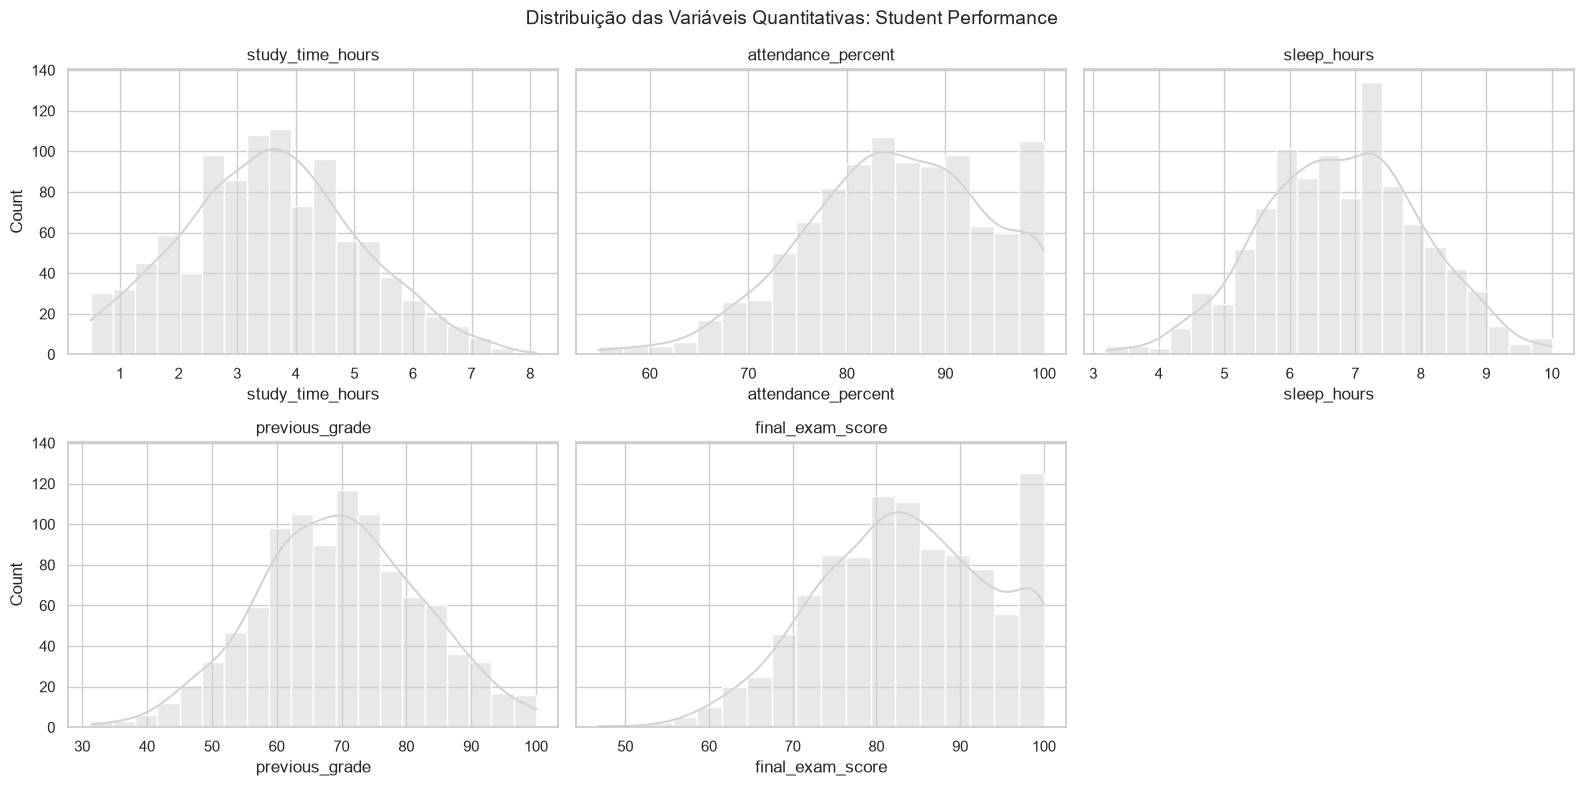

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: Student Performance", fontsize=14)
plt.tight_layout()
plt.show()

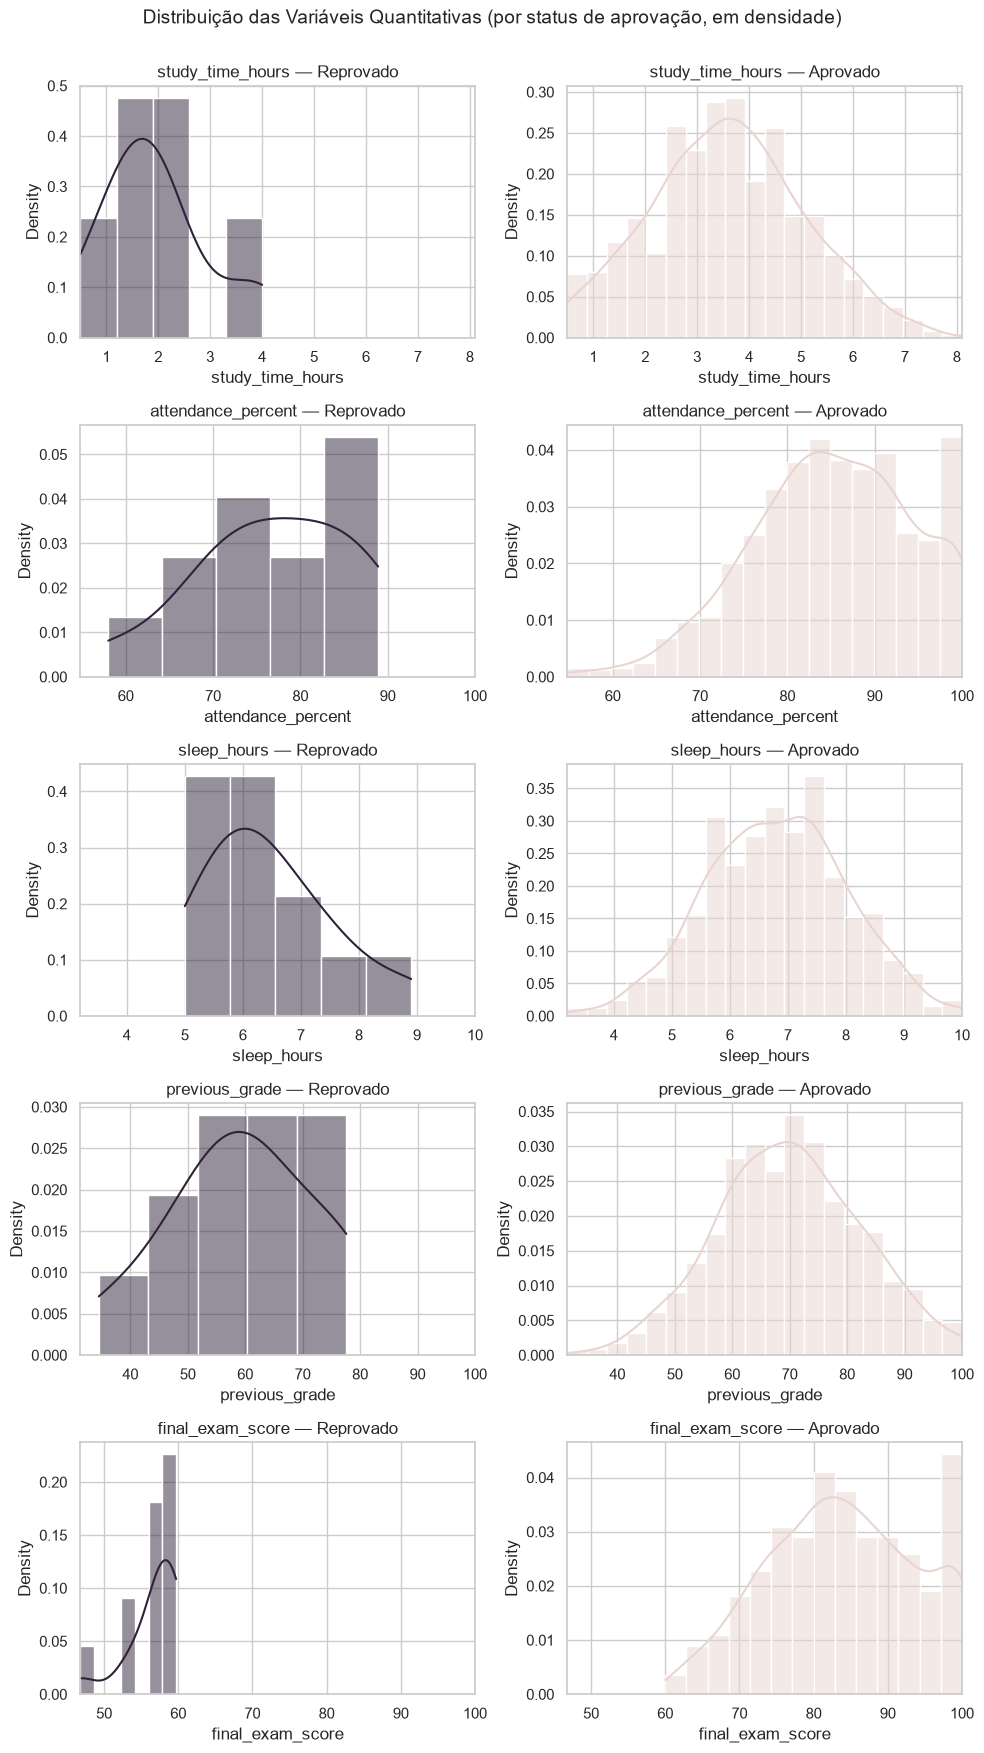

In [14]:
fig, axes = plt.subplots(
    len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=False
)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    for j, (classe, cor) in enumerate(
        [("Reprovado", COR_DESTAQUE), ("Aprovado", COR_CONTEXTO)]
    ):
        subset = df[df["status_aprovacao"] == classe]
        sns.histplot(
            data=subset,
            x=col,
            kde=True,
            color=cor,
            ax=axes[i, j],
            stat="density",
            common_norm=False,
        )
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle(
    "Distribuição das Variáveis Quantitativas (por status de aprovação, em densidade)",
    fontsize=14,
    y=1.001,
)
plt.tight_layout()
plt.show()

### Para discutir: Comparação das Distribuições por Classe

* **Comportamento Geral dos Formatos:**
  * As distribuições apresentam baixa assimetria e, em geral, formatos unimodais. A comparação entre aprovados e reprovados deve ser feita com cautela porque o grupo de reprovados possui apenas 12 observações.

* **Diferenças Notáveis entre "Reprovado" e "Aprovado":**
  * **Deslocamento na Escala (`final_exam_score`):** A diferença mais marcante não é o formato da curva, mas o **deslocamento no eixo X**. O grupo de *Reprovados* fica concentrado estritamente na faixa inferior a 60 (piso biológico/metodológico do critério), enquanto o grupo de *Aprovados* ocupa de 60 a 100 com concentração nos valores mais altos.
  * **Comportamento de Frequência (`attendance_percent` e `study_time_hours`):** Os estudantes reprovados tendem a apresentar curvas ligeiramente mais achatadas e deslocadas para a esquerda (menores médias de presença e tempo de estudo), enquanto os aprovados apresentam assimetria à esquerda acentuada em frequência escolar (`attendance_percent`), com pico perto dos 100%.
  * **Estabilidade de Formato (`sleep_hours`):** A variável de horas de sono mantém formato quase idêntico e centrado entre ambos os grupos, demonstrando pouca capacidade de separação entre as classes.

#### Testes de Aderência

*Será se o tempo de estudo segue uma distribuição normal?*

O **Shapiro-Wilk** é um teste de aderência utilizado para verificar normalidade, acompanhado do **QQ-Plot** como visualização de apoio. Vamos realizar o teste utilizando a variável `study_time_hours`.

Shapiro-Wilk — study_time_hours: estatística=0.9935, p-valor=0.0002468
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


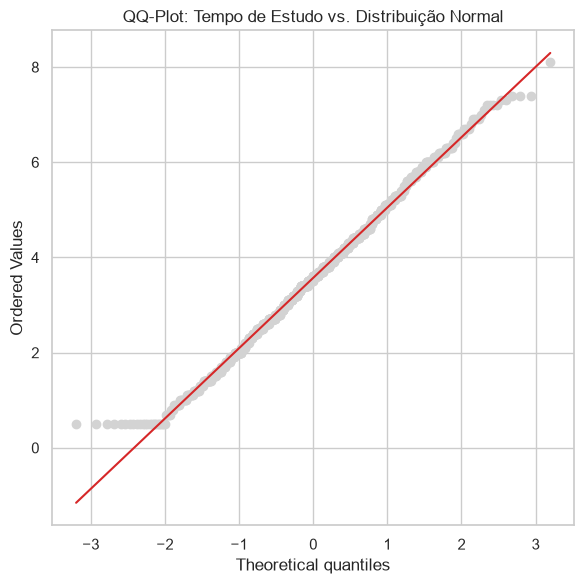

In [15]:
stat_sw, p_valor_sw = stats.shapiro(df["study_time_hours"].dropna())
print(
    f"Shapiro-Wilk — study_time_hours: estatística={stat_sw:.4f},"
    f" p-valor={p_valor_sw:.4g}"
)
print(
    "Rejeita H0 (normalidade)?",
    "Sim" if p_valor_sw < 0.05 else "Não",
    "(alpha = 0.05)",
)

"""### QQ-Plot — Tempo de Estudo (study_time_hours)"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["study_time_hours"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Tempo de Estudo vs. Distribuição Normal")
plt.tight_layout()
plt.show()


**Como ler:** se os pontos seguissem a reta de referência de perto, a variável teria comportamento mais próximo de uma normal. Afastamentos sistemáticos, principalmente nas pontas, indicam diferenças em relação à distribuição normal teórica.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** com 1000 observações, o Shapiro-Wilk possui bastante sensibilidade a pequenos desvios da normalidade. Por isso, o resultado deve ser interpretado junto com skewness, kurtosis e QQ-Plot.
- **Como afirmar o resultado:** quando o teste **rejeita** $H_0$ ($p < 0.05$), a afirmação correta é que temos evidência estatística **contra** a normalidade. Isso não significa que a distribuição seja completamente diferente de uma normal em todos os aspectos.


In [16]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
study_time_hours,0.9935,0.000247,True
attendance_percent,0.9787,0.000000,True
sleep_hours,0.9977,0.175638,False
previous_grade,0.9973,0.099874,False
final_exam_score,0.9772,0.000000,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`final_exam_score`, nota do exame final), só pra fixar como essa visualização se lê.

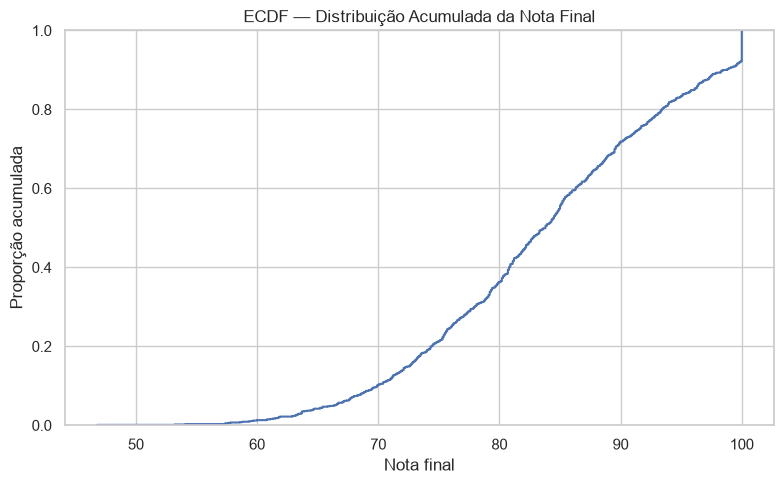

In [17]:
plt.figure(figsize=(8, 5))

sns.ecdfplot(data=df, x="final_exam_score")

plt.title("ECDF — Distribuição Acumulada da Nota Final")
plt.xlabel("Nota final")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos estudantes desse grupo tem nota até aqui". Onde as duas curvas se distanciam mais, ali está a faixa de desempenho onde os dois grupos mais diferem, sem precisar decidir uma largura de *bin* como no histograma.

### Métricas de Tendêncial Central

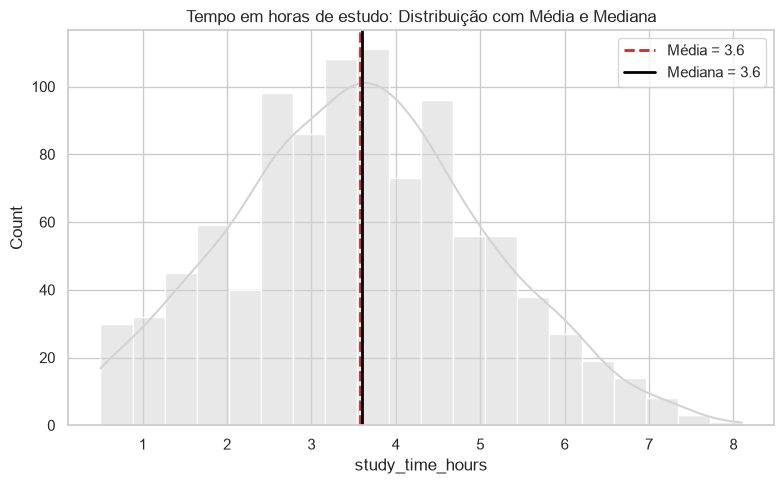

In [18]:
media_study_time_hours = df["study_time_hours"].mean()
mediana_study_time_hours = df["study_time_hours"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="study_time_hours", kde=True, color=COR_NEUTRA)
plt.axvline(media_study_time_hours, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_study_time_hours:.1f}")
plt.axvline(mediana_study_time_hours, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_study_time_hours:.1f}")
plt.title("Tempo em horas de estudo: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

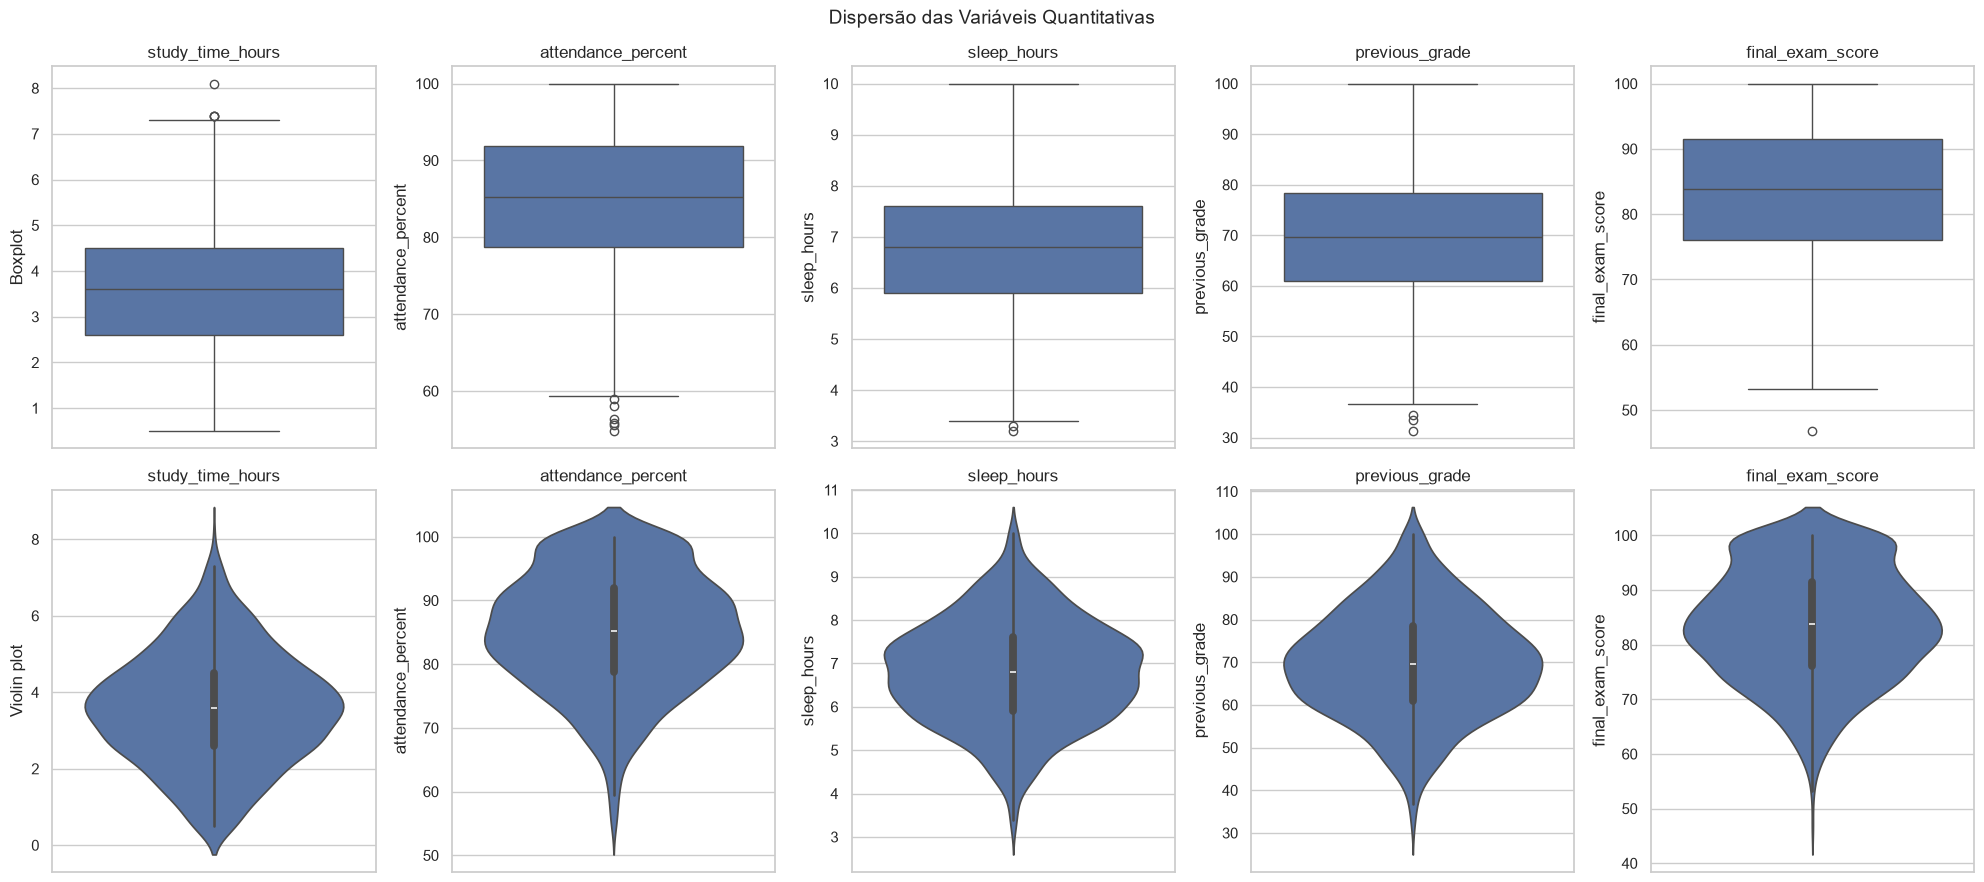

In [19]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot"""

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, y=col, ax=axes[1, i])
    axes[1, i].set_title(col)
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")

fig.suptitle("Dispersão das Variáveis Quantitativas", fontsize=14)
plt.tight_layout()
plt.show()

### Para discutir: Análise dos Boxplots e Violin Plots

* **Limitação dos Gráficos Atuais:**
  * Nos gráficos gerados acima, todas as observações foram plotadas em **uma única caixa/violino por variável** (dataset completo unificado), sem segmentação entre as classes de status de aprovação.
  * Para avaliar se o intervalo interquartil (IQR) difere entre os grupos, os gráficos precisariam utilizar o parâmetro `hue="status_aprovacao"` ou estar divididos por classe.

* **O que podemos inferir com base no comportamento geral dos dados:**
  * **`final_exam_score` e `attendance_percent`:** São as candidatas mais fortes a apresentar caixas (IQR) em patamares completamente distintos entre aprovados e reprovados. Como a aprovação exige nota mínima de 60, o IQR de `final_exam_score` para os aprovados estará posicionado bem mais ao alto do eixo Y (faixa de 60 a 100) do que o dos reprovados (faixa de 0 a 59).
  * **`study_time_hours` e `previous_grade`:** Tendem a apresentar caixas moderadamente separadas, com a mediana do grupo aprovado ligeiramente superior.
  * **`sleep_hours`:** Como visto nas análises anteriores, a distribuição das horas de sono é muito homogênea, indicando que o IQR dessa variável deve ficar praticamente na mesma altura para ambos os grupos.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava para decidir como tratar os dados ausentes (`parental_education`) e avaliar os outliers das variáveis quantitativas (`study_time_hours`, `attendance_percent`, `sleep_hours`, `previous_grade` e `final_exam_score`). Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") para confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [20]:
df_antes = df.copy()

def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
study_time_hours,-0.25,7.35,4.0
attendance_percent,59.15,111.55,6.0
sleep_hours,3.35,10.15,2.0
previous_grade,34.90,104.50,3.0
final_exam_score,52.90,114.70,1.0


### Visualizando os Outliers

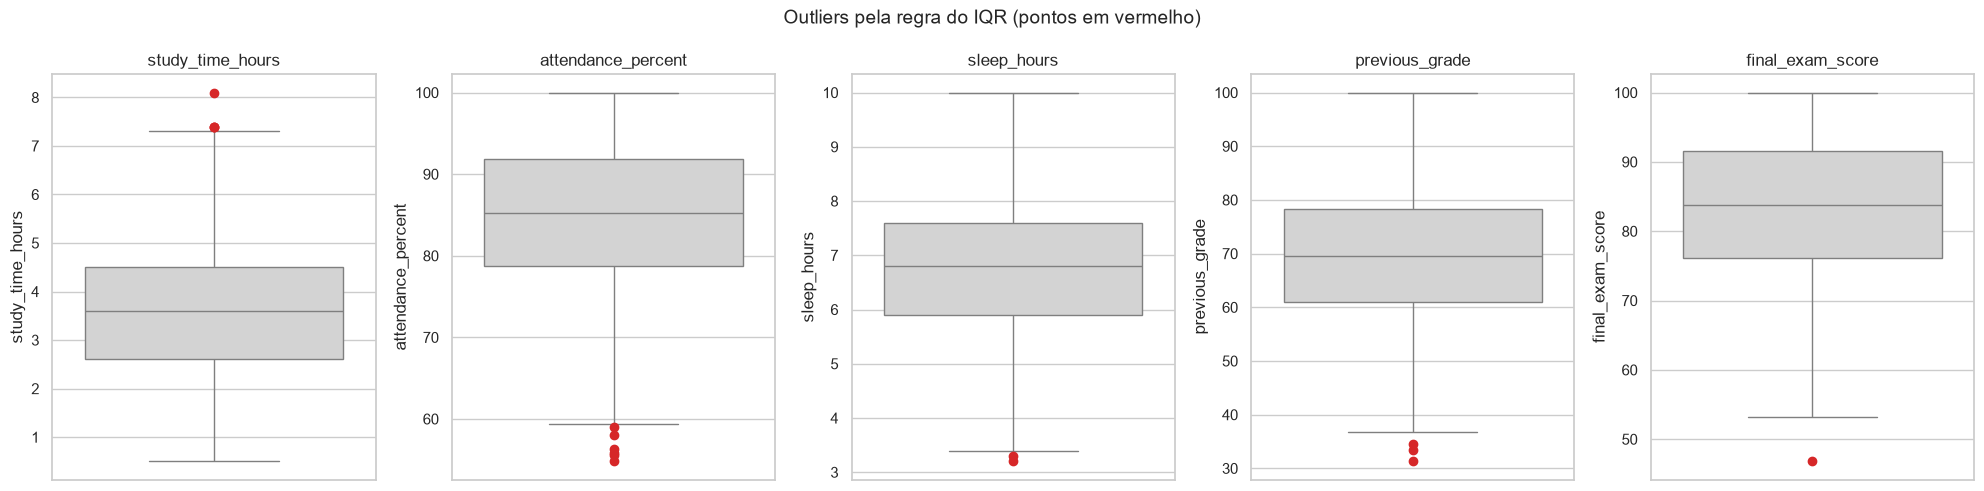

In [21]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

### Para discutir: Classificação e Tratamento dos Outliers Encontrados

* **Classificação por Domínio Educacional:**
  * **Outliers Estatísticos (Legítimos):** Todos os valores detectados pela regra do IQR se enquadram como **Outliers Estatísticos**. Eles representam comportamentos e desempenhos reais, porém extremos, de estudantes reais:
    * **`study_time_hours` (4 outliers > 7.35h):** Alunos que estudam em torno de 8h/dia. É um valor alto, mas plenamente possível.
    * **`attendance_percent` (6 outliers < 59.15%):** Alunos com frequência entre 54% e 58%. São estudantes com baixa assiduidade, mas dentro do limite possível (0–100%).
    * **`sleep_hours` (2 outliers < 3.35h):** Alunos que dormem pouco mais de 3 horas por noite — cenário plausível no contexto de rotina de estudos intensa.
    * **`previous_grade` (3 outliers < 34.90%) e `final_exam_score` (1 outlier < 52.90%):** Notas baixas (ex: 31 e 46.8), perfeitamente válidas em um sistema de pontuação de 0 a 100.

* **Violação de Regras de Negócio / Erros de Dados:**
  * **Nenhum valor viola o domínio.** Não há notas negativas ou superiores a 100, porcentagens de presença fora da faixa [0, 100] ou horas diárias surreais (como 25h). Não há indício de erro de digitação ou falha no sistema de coleta.

* **Recomendação de Tratamento:**
  * **Manter os dados:** Como se tratam de variações biológicas/comportamentais legítimas do contexto educacional, **não devemos remover as linhas**. Remover esses pontos eliminaria informações valiosas sobre alunos de baixíssimo rendimento ou altamente dedicados.
  * **Ação:** Manter os dados em sua forma original ou optar por técnicas estatísticas robustas (como uso da mediana e modelos não paramétricos ou baseados em árvores, que não são sensíveis a esses valores).

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: a variável com dados ausentes é `parental_education`, e o volume de dados faltantes é relativamente baixo no contexto da base. A decisão pragmática para a variável categórica é preenchê-la com a moda da coluna (`"High School"`). Dessa forma, evitamos a perda desnecessária de observações e preservamos todas as demais informações dos estudantes para a análise.

In [22]:
linhas_antes = df.shape[0]
faltantes = df["parental_education"].isna().sum()
percentual_faltantes = (faltantes / linhas_antes) * 100

print(f"Linhas antes: {linhas_antes}")
print(f"Dados ausentes em parental_education: {faltantes}")
print(f"Percentual de dados ausentes: {percentual_faltantes:.2f}%")

moda = df["parental_education"].mode()[0]
df["parental_education"] = df["parental_education"].fillna(moda)

print(f"Valor utilizado para preencher os dados ausentes: {moda}")
print(f"Dados ausentes após o tratamento: {df['parental_education'].isna().sum()}")

Linhas antes: 1000
Dados ausentes em parental_education: 102
Percentual de dados ausentes: 10.20%
Valor utilizado para preencher os dados ausentes: High School
Dados ausentes após o tratamento: 0


### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas educacionalmente plausíveis, ainda que pontuais), a classificação mais provável é **"Estatístico"**, ou seja, outliers legítimos e não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser pedagogicamente relevante — por exemplo, estudantes com hábitos extremos de estudo ou baixíssima assiduidade podem representar casos críticos de acompanhamento) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `study_time_hours` — útil caso, em análises futuras, a assimetria atrapalhe algum teste ou modelo.

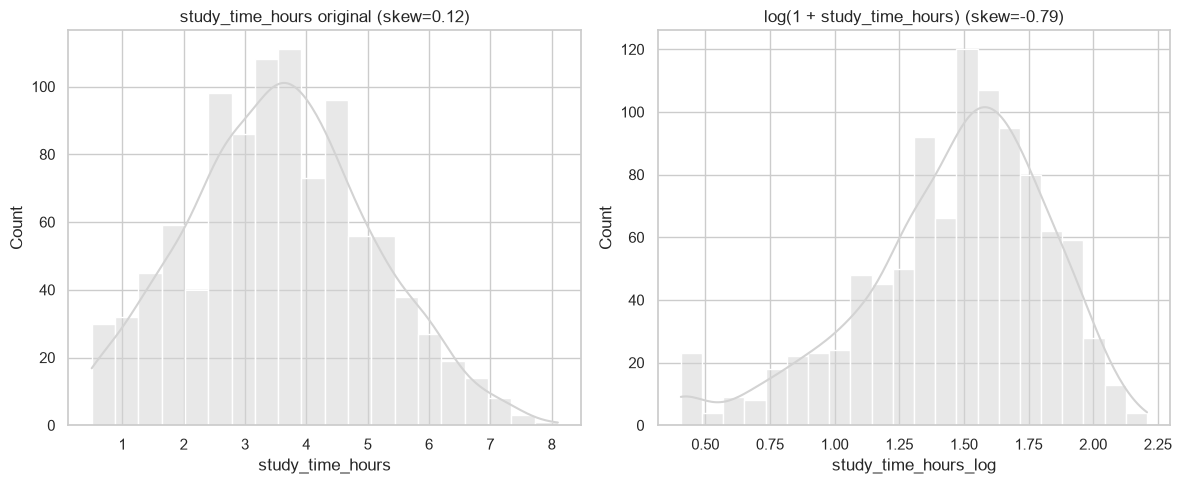

In [23]:
df["study_time_hours_log"] = np.log1p(df["study_time_hours"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(
    data=df, x="study_time_hours", kde=True, color=COR_NEUTRA, ax=axes[0]
)
axes[0].set_title(
    f"study_time_hours original (skew={df['study_time_hours'].skew():.2f})"
)

sns.histplot(
    data=df, x="study_time_hours_log", kde=True, color=COR_NEUTRA, ax=axes[1]
)
axes[1].set_title(
    "log(1 + study_time_hours)"
    f" (skew={df['study_time_hours_log'].skew():.2f})"
)

plt.tight_layout()
plt.show()

### Para discutir: Avaliação da Transformação Logarítmica

* **Efeito na Assimetria:**
  * **Não reduziu a assimetria — na verdade, piorou.**
  * A variável original `study_time_hours` já possuía uma distribuição praticamente simétrica ($\text{skew} = 0.12$).
  * Aplicar a transformação logarítmica em dados que já são simétricos causou uma **supercorreção**, introduzindo uma assimetria negativa moderada ($\text{skew} = -0.79$) e esticando a cauda para a esquerda.
  * A transformação logarítmica é indicada para distribuições com assimetria positiva acentuada ($\text{skew} > 1.0$), como renda ou colesterol, mas **não deve ser aplicada em variáveis previamente simétricas**.

* **Decisão do Projeto:**
  * Mantivemos `study_time_hours_log` apenas como uma demonstração didática do efeito da função logarítmica, mas **não a usaremos nas próximas seções**. Utilizaremos a variável em sua escala original.

* **Nota Geral sobre Outliers:**
  * Nem todo outlier deve ser removido. Antes de tomar uma decisão, classifique-os:
    * **Estatisticamente raro, porém plausível:** Manter na escala original ou transformar (se houver assimetria positiva acentuada).
    * **Violação de regras de negócio/físicas:** Investigar a origem da inconsistência antes de decidir.
    * **Erro claro de digitação ou coleta:** Corrigir a informação se houver fonte confiável ou remover o dado.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [24]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
study_time_hours,3.57,3.60,1.48,0.50,8.10,0.12,-0.34
attendance_percent,85.09,85.20,9.27,54.80,100.00,-0.34,-0.26
sleep_hours,6.80,6.80,1.20,3.20,10.00,-0.02,-0.22
previous_grade,69.74,69.60,12.61,31.30,100.00,0.00,-0.24
final_exam_score,83.54,83.80,10.34,46.80,100.00,-0.22,-0.51


### Comparando "antes" x "depois"


In [25]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
study_time_hours,0.121,0.121,-0.340,-0.340,0.0,0.0
attendance_percent,-0.337,-0.337,-0.261,-0.261,0.0,0.0
sleep_hours,-0.023,-0.023,-0.218,-0.218,0.0,0.0
previous_grade,0.001,0.001,-0.238,-0.238,0.0,0.0
final_exam_score,-0.219,-0.219,-0.511,-0.511,0.0,0.0


### Para discutir: Por que as métricas "antes" e "depois" permaneceram idênticas?

* **Manutenção dos Outliers Numéricos:** Os valores identificados pela regra do IQR foram considerados plausíveis dentro do domínio educacional. Por isso, optamos por **não remover nem transformar** as observações quantitativas.
* **Isolamento dos Dados Ausentes:** O tratamento de dados faltantes foi aplicado exclusivamente à coluna `parental_education`, que é categórica, não alterando as variáveis quantitativas usadas na estatística descritiva.
* **Conclusão:** Como nenhuma observação quantitativa foi modificada, as medidas de skewness e kurtosis permanecem iguais antes e depois.


**A nota do exame final ainda rejeita a normalidade?**

Vamos rodar o mesmo teste de Shapiro-Wilk da Seção 3, agora para `final_exam_score`, comparando os dados antes e depois do tratamento.


In [26]:
stat_sw_antes, p_valor_sw_antes = stats.shapiro(df_antes["final_exam_score"].dropna())

stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["final_exam_score"].dropna())

print(f"Shapiro-Wilk (antes)  — final_exam_score: estatística={stat_sw_antes:.4f}, p-valor={p_valor_sw_antes:.4g}")
print(f"Shapiro-Wilk (depois) — final_exam_score: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")


Shapiro-Wilk (antes)  — final_exam_score: estatística=0.9772, p-valor=2.056e-11
Shapiro-Wilk (depois) — final_exam_score: estatística=0.9772, p-valor=2.056e-11


**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`study_time_hours` e `final_exam_score`), comparando a versão original (`df_antes`) com a tratada (`df`). Como mantivemos os dados originais, as curvas de densidade do "Antes" e do "Depois" ficarão perfeitamente sobrepostas, ilustrando graficamente a preservação integral da distribuição.

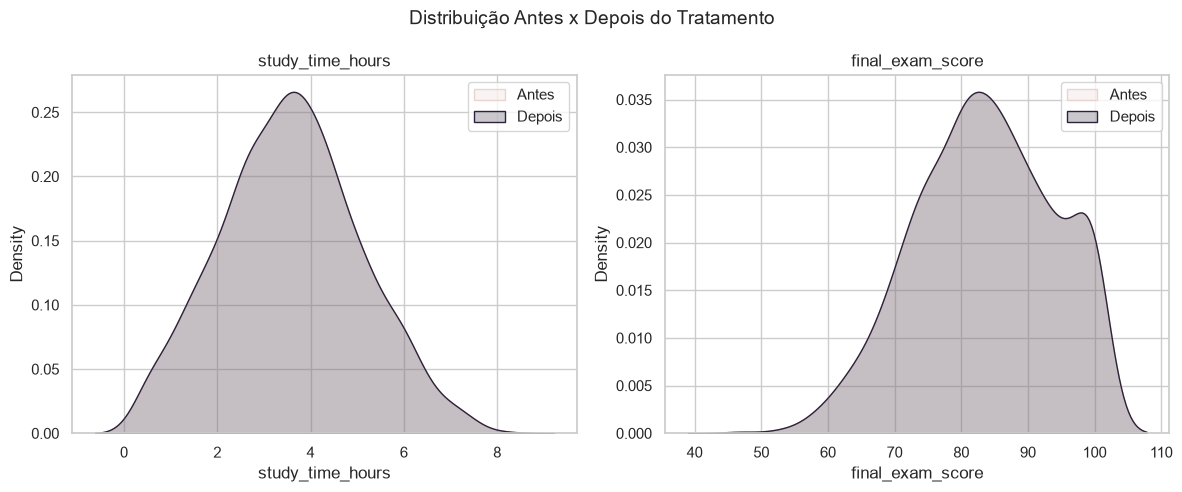

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["study_time_hours", "final_exam_score"]):
    sns.kdeplot(
        df_antes[col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax
    )
    sns.kdeplot(df[col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()


**A nota do exame final ainda rejeita a normalidade?**

Como mantivemos todas as observações de `final_exam_score`, o resultado do teste de Shapiro-Wilk antes e depois permanece igual. O p-valor permanece abaixo de 0,05, portanto há evidência estatística contra a normalidade da variável. Como a amostra possui 1000 observações, essa conclusão deve ser interpretada em conjunto com o QQ-Plot e as medidas de assimetria e curtose.


## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [28]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- gender ---
        absoluta  relativa
gender                    
Female       510      0.51
Male         490      0.49
\n--- parental_education ---
                    absoluta  relativa
parental_education                    
High School              458     0.458
Bachelors                308     0.308
Masters                  184     0.184
PhD                       50     0.050
\n--- internet_access ---
                 absoluta  relativa
internet_access                    
Yes                   854     0.854
No                    146     0.146
\n--- extracurricular_activities ---
                            absoluta  relativa
extracurricular_activities                    
Yes                              572     0.572
No                               428     0.428
\n--- part_time_job ---
               absoluta  relativa
part_time_job                    
No                  684     0.684
Yes                 316     0.316
\n--- final_grade ---
             absoluta  relativa
fin

#### Visualizando as frequências

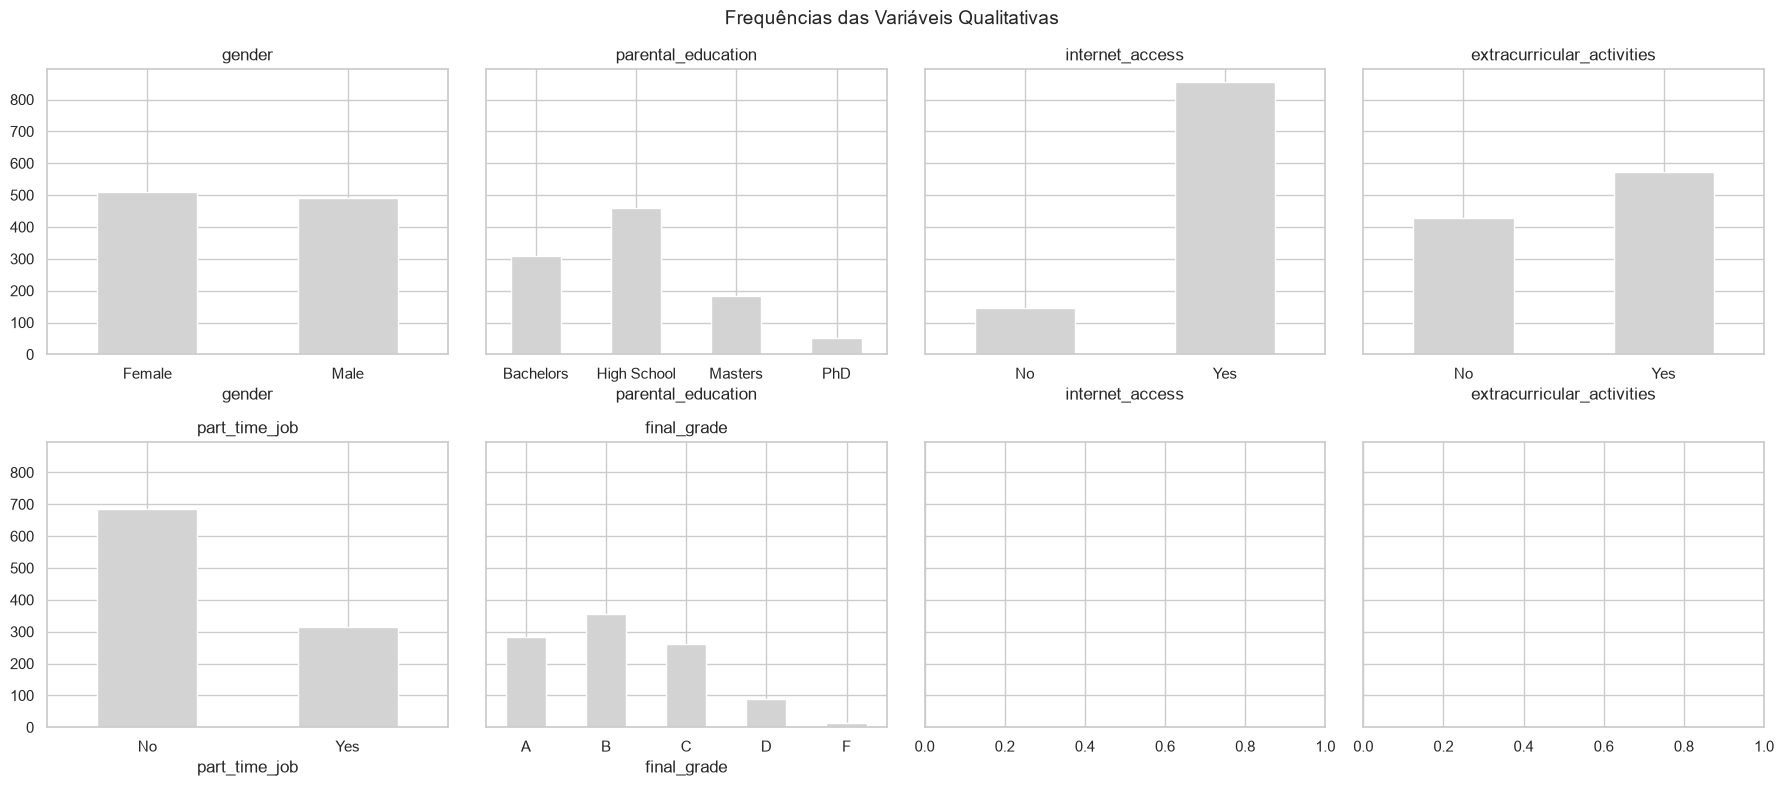

In [29]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

### Para discutir: Desbalanceamento nas Variáveis Qualitativas

* **`internet_access` (Fortemente Desbalanceada):**
  * A categoria **"Yes"** domina de forma esmagadora o conjunto de dados (com mais de 800 observações), enquanto a categoria **"No"** conta com pouco menos de 150 estudantes.
  * **Impacto na Análise Bivariada:** Esse desbalanceamento expressivo exige cuidado. Ao cruzar `internet_access` com a taxa de aprovação ou com as notas, a baixa quantidade de alunos na categoria "No" pode gerar proporções menos estáveis ou mascarar efeitos reais devido ao tamanho amostral reduzido nesse grupo.

* **`part_time_job` e `extracurricular_activities` (Moderadamente Desbalanceadas):**
  * Apresentam uma distribuição assimétrica, mas dentro de limites razoáveis de comparação. Em `part_time_job`, a maioria expressiva dos alunos não trabalha ("No" ~680 vs. "Yes" ~310).

* **`gender` e `final_grade` (Bem Distribuídas):**
  * `gender` possui uma divisão quase perfeitamente equilibrada (50/50) entre Female e Male.
  * `final_grade` segue uma distribuição ordinal esperada e bem gradativa, concentrando-se nas notas intermediárias (B, A, C) com pouquíssimas ocorrências nos extremos mais baixos (D, F).

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `status_aprovacao`.

In [30]:
from scipy.stats import entropy


def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = (
        entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    )
    return pd.Series(
        {
            "n_classes": n_classes,
            "razao_desbalanceamento": round(razao, 2),
            "entropia_normalizada": round(ent_normalizada, 3),
        }
    )


vars_para_checar = VARS_QUALI + ["status_aprovacao"]
pd.DataFrame(
    {col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}
).T

,n_classes,razao_desbalanceamento,entropia_normalizada
gender,2.0,1.04,1.000
parental_education,4.0,9.16,0.852
internet_access,2.0,5.85,0.600
extracurricular_activities,2.0,1.34,0.985
part_time_job,2.0,2.16,0.900
final_grade,5.0,29.50,0.835
status_aprovacao,2.0,82.33,0.094


### Para discutir: Avaliação do Desbalanceamento e Entropia

* **Alvo Desbalanceado:**
  * **`status_aprovacao`** apresenta entropia normalizada de **0.094** e razão de desbalanceamento de **82.33**, pois há **988 aprovados e apenas 12 reprovados**. Isso caracteriza forte desbalanceamento da variável alvo.
  * **`internet_access`** apresenta entropia normalizada de **0.600** e razão de **5.85**, refletindo a predominância da categoria `Yes`.

* **Impacto no Alvo (`status_aprovacao`):**
  * O pequeno número de reprovados exige cautela na interpretação de proporções e testes estatísticos por classe.
  * Em uma modelagem futura, seria importante considerar métricas adequadas para classes desbalanceadas, como precisão, recall, F1-Score e PR-AUC, além da acurácia.

* **Demais Preditoras:**
  * `gender` apresenta equilíbrio praticamente perfeito (entropia = 1.000).
  * `extracurricular_activities`, `part_time_job`, `parental_education` e `final_grade` apresentam diversidade entre suas categorias, embora em diferentes níveis de equilíbrio.


### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo `status_aprovacao`.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

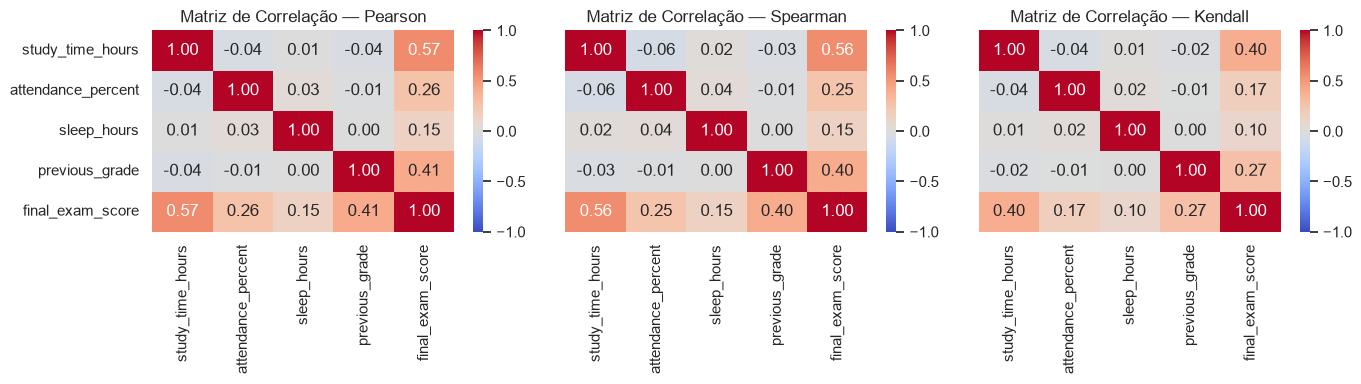

In [31]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


w

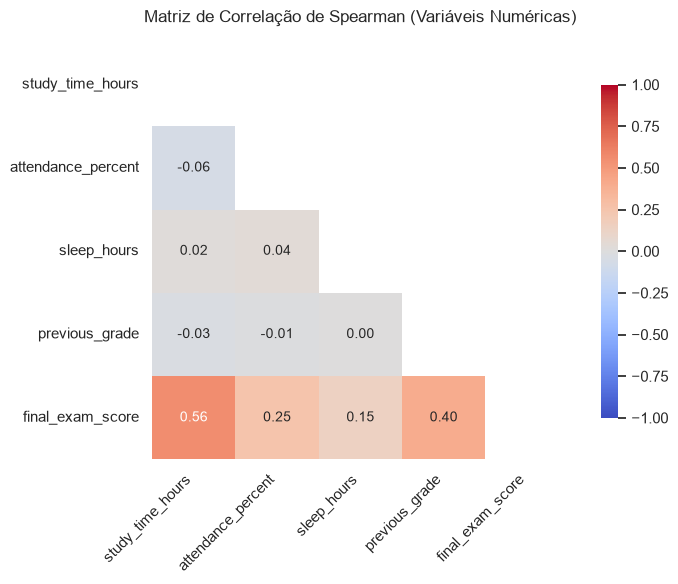

In [32]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")

mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_spearman,
    mask=mask,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    square=True,
    vmin=-1,
    vmax=1,
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 10},
)

plt.title("Matriz de Correlação de Spearman (Variáveis Numéricas)", pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.grid(False)
plt.tight_layout()
plt.show()

### Para discutir: Comparação entre Pearson e Spearman

* **Ausência de Divergências Significativas:**
  * **Valores Praticamente Idênticos:** Os coeficientes de Pearson e Spearman apresentam variações insignificantes em todos os pares (diferenças de apenas $0.01$, como em `study_time_hours` vs `final_exam_score`, que varia de $0.57$ para $0.56$).
  * **Conclusão de Linearidade:** A proximidade quase perfeita entre os dois coeficientes indica que **não há evidências de relações não-lineares monotônicas ocultas**. As associações identificadas comportam-se de maneira essencialmente linear no espaço dos dados.

* **Comportamento das Relações Chave:**
  * `study_time_hours` mantém forte associação linear com `final_exam_score` ($0.57$ em Pearson e $0.56$ em Spearman).
  * `previous_grade` sustenta relevância direta sobre a nota final ($0.41$ em Pearson e $0.40$ em Spearman).
  * As variáveis de suporte (`attendance_percent` e `sleep_hours`) permanecem com fraco impacto linear/monotônico ($0.26$/$0.25$ e $0.15$/$0.15$).

* **Observação sobre o Coeficiente de Kendall:**
  * Os valores de Kendall aparecem naturalmente menores (ex.: $0.40$ para horas de estudo vs nota final), o que é matematicamente esperado devido à sua mecânica baseada em pares concordantes e discordantes, mantendo contudo a exata mesma hierarquia de importância entre as variáveis.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `study_time_hours` x `final_exam_score` por um motivo de domínio, não só estatístico: existe uma relação pedagógica clara entre o tempo dedicado aos estudos e o desempenho acadêmico, o que torna esse par um excelente candidato para visualizar uma tendência real de aprendizado.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com a maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

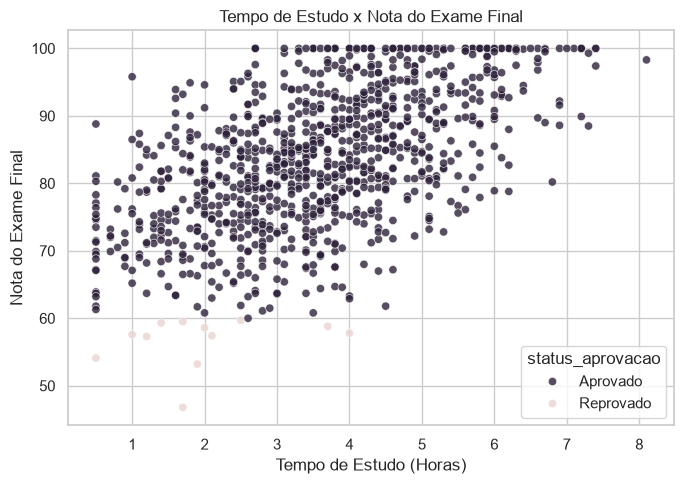

In [33]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="study_time_hours",
    y="final_exam_score",
    hue="status_aprovacao",
    palette={"Aprovado": COR_DESTAQUE, "Reprovado": COR_CONTEXTO},
    alpha=0.8,
)
plt.title("Tempo de Estudo x Nota do Exame Final")
plt.xlabel("Tempo de Estudo (Horas)")
plt.ylabel("Nota do Exame Final")
plt.tight_layout()
plt.show()

### Para discutir: Análise do Scatter Plot (`study_time_hours` x `final_exam_score`)

* **Tendência Positiva Clara:**
  * À medida que o tempo de estudo (`study_time_hours`) aumenta, a nota do exame final (`final_exam_score`) apresenta uma tendência ascendente nítida.
  * Estudantes com menos de 2 horas de estudo concentram-se predominantemente em notas entre 60 e 80, enquanto a partir de 4 a 5 horas de estudo a grande maioria atinge notas superiores a 80 (com um teto visível em 100).

* **Separação das Classes de `status_aprovacao`:**
  * **Separação Horizontal/Vertical:** A classe **"Reprovado"** (pontos claros) está estritamente delimitada pela região inferior do gráfico (notas abaixo de 60), enquanto a classe **"Aprovado"** ocupa toda a região superior.
  * **Faixa Crítica de Horas:** Observa-se que todos os alunos reprovados dedicaram 4 horas ou menos de estudo. Não há registros de alunos reprovados acima de 4 horas de estudo no conjunto de dados, indicando que uma carga horária mais alta atua como uma forte salvaguarda contra a reprovação.


#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [34]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_aprovado = df.loc[df["status_aprovacao"] == "Aprovado", col]
    grupo_reprovado = df.loc[df["status_aprovacao"] == "Reprovado", col]

    stat_t, p_t = stats.ttest_ind(
        grupo_aprovado, grupo_reprovado, equal_var=False
    )
    stat_u, p_u = stats.mannwhitneyu(grupo_aprovado, grupo_reprovado)

    resultados_comparacao.append(
        {
            "variavel": col,
            "p_valor_ttest": round(p_t, 5),
            "p_valor_mannwhitney": round(p_u, 5),
            "concordam": (p_t < 0.05) == (p_u < 0.05),
        }
    )

pd.DataFrame(resultados_comparacao).set_index("variavel")

,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
study_time_hours,0.00019,0.00018,True
attendance_percent,0.01074,0.00551,True
sleep_hours,0.31315,0.22165,True
previous_grade,0.01747,0.01054,True
final_exam_score,0.00000,0.00000,True


### Para discutir: Concordância dos Testes Bivariados entre Grupos (`status_aprovacao`)

* **Concordância Total (100% de Alinhamento):**
  * Observando a tabela de resultados, a coluna **`concordam` é `True` para todas as variáveis quantitativas**.
  * Ambos os testes (T-Test e Mann-Whitney U) chegaram exatamente às mesmas conclusões em relação à significância estatística ao nível de $\alpha = 0.05$.

* **Variáveis Estatisticamente Significativas ($p < 0.05$):**
  * **`study_time_hours` ($p \approx 0.00018$):** Confirma que o tempo de estudo difere de forma extremamente relevante entre aprovados e reprovados.
  * **`final_exam_score` ($p < 0.00001$):** A nota final apresenta a diferença mais acentuada entre os grupos de aprovação, sendo o principal divisor direto dos estudantes.
  * **`attendance_percent` ($p \approx 0.00551$) e `previous_grade` ($p \approx 0.01054$):** Ambas também apresentam diferenças estatisticamente significativas entre as classes de aprovação.

* **Variável Não Significativa ($p \ge 0.05$):**
  * **`sleep_hours` ($p \approx 0.22165$):** O teste não encontrou diferença estatisticamente significativa nas horas de sono entre alunos aprovados e reprovados.

* **Decisão Metodológica:**
  * Embora o T-Test tenha chegado às mesmas conclusões, o **Mann-Whitney U** deve ser rigorosamente priorizado e reportado como o teste oficial na análise final. Como os dados violaram a suposição de normalidade no teste de Shapiro-Wilk, o uso do teste não-paramétrico respeita a verdadeira natureza da distribuição observada.

ANOVA          — final_exam_score por parental_education: estatística=0.618, p-valor=0.60346
Kruskal-Wallis — final_exam_score por parental_education: estatística=1.581, p-valor=0.66364


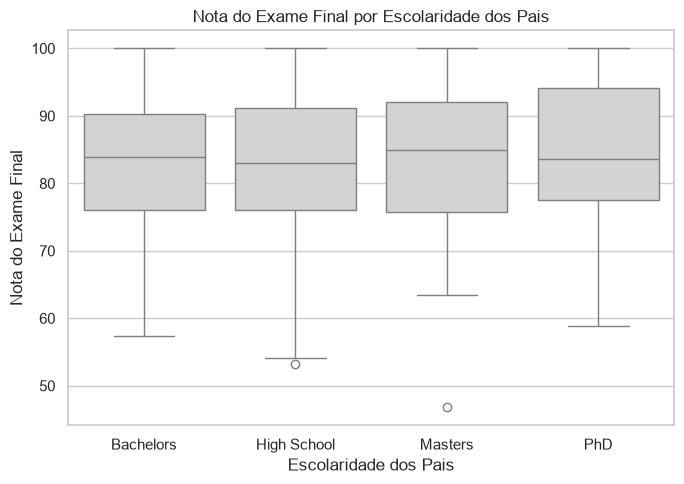

In [35]:
grupos_edu = [
    grupo["final_exam_score"].values
    for _, grupo in df.groupby("parental_education")
]

stat_anova, p_anova = stats.f_oneway(*grupos_edu)
stat_kw, p_kw = stats.kruskal(*grupos_edu)

print(
    f"ANOVA          — final_exam_score por parental_education: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}"
)
print(
    f"Kruskal-Wallis — final_exam_score por parental_education: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}"
)

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="parental_education", y="final_exam_score", color=COR_NEUTRA)
plt.title("Nota do Exame Final por Escolaridade dos Pais")
plt.xlabel("Escolaridade dos Pais")
plt.ylabel("Nota do Exame Final")
plt.tight_layout()
plt.show()

### Para discutir: Concordância nos Testes e Interpretação do Boxplot

* **Concordância entre os Testes (ANOVA vs. Kruskal-Wallis):**
  * **Conclusão Estatística:** Ambos os testes apontam para a **não rejeição da hipótese nula** ($p\text{-valor} \ge 0.05$). Não há diferença estatisticamente significativa na mediana ou na média da nota do exame final (`final_exam_score`) entre os diferentes níveis de escolaridade dos pais (`parental_education`).
  * **Uso do Teste Não-Paramétrico:** Como a variável `final_exam_score` violou o pressuposto de normalidade no teste de Shapiro-Wilk, o **Kruskal-Wallis** é o teste oficial e robusto a ser reportado no relatório, mantendo a ANOVA apenas como um ponto de contraste empírico.

* **Análise Visual do Boxplot:**
  * **Medianas Semelhantes:** As linhas centrais das caixas (`Bachelors`, `High School`, `Masters` e `PhD`) estão praticamente alinhadas na faixa dos 83 a 85 pontos.
  * **Variabilidade Parecida:** A amplitude interquartil (IQR) é quase idêntica em todas as categorias, variando aproximadamente de 76 a 92 pontos.
  * **Presença de Outliers:** Notam-se apenas pequenos valores atípicos inferiores nos grupos de escolaridade `High School` e `Masters` (notas pontuais abaixo de 60), que não afetam a distribuição geral a ponto de criar diferenças significativas entre os grupos.

#### Quantitativa x Qualitativa

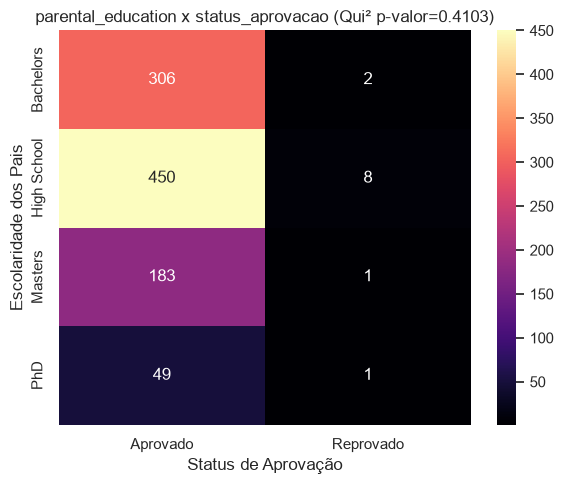

In [36]:
contingencia_edu = pd.crosstab(df["parental_education"], df["status_aprovacao"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_edu)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_edu, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"parental_education x status_aprovacao (Qui² p-valor={p_chi2:.4g})")
plt.xlabel("Status de Aprovação")
plt.ylabel("Escolaridade dos Pais")
plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica se existe associação estatisticamente significativa entre `parental_education` e `status_aprovacao`?

**Análise do Teste de Qui-Quadrado:**

O teste apresentado no código compara a escolaridade dos pais com o status de aprovação. O p-valor obtido foi aproximadamente $p = 0{,}4103$. Como $p > 0{,}05$, não há evidências suficientes para rejeitar a hipótese nula de independência. Portanto, nesta amostra, não foi identificada associação estatisticamente significativa entre `parental_education` e `status_aprovacao`.


#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta de forma semelhante em diferentes subgrupos? Nesta análise, observamos **sexo** e **faixas de tempo de estudo**. Como o dataset não possui idade, não utilizamos faixa de tempo de estudo. A análise serve para mapear diferenças observadas na amostra antes de qualquer modelagem.


In [37]:
df["sexo_label"] = df["gender"].map({"Female": "Feminino", "Male": "Masculino"})
df["faixa_estudo"] = pd.cut(
    df["study_time_hours"],
    bins=[0, 2, 4, 6, 10],
    labels=["<2h", "2-4h", "4-6h", ">6h"]
)

print("Desbalanceamento — sexo:")
print(metrica_desbalanceamento(df["sexo_label"]))
print("\nDesbalanceamento — faixa de tempo de estudo:")
print(metrica_desbalanceamento(df["faixa_estudo"]))

Desbalanceamento — sexo:
n_classes                 2.00
razao_desbalanceamento    1.04
entropia_normalizada      1.00
dtype: float64

Desbalanceamento — faixa de tempo de estudo:
n_classes                 4.000
razao_desbalanceamento    8.980
entropia_normalizada      0.845
dtype: float64


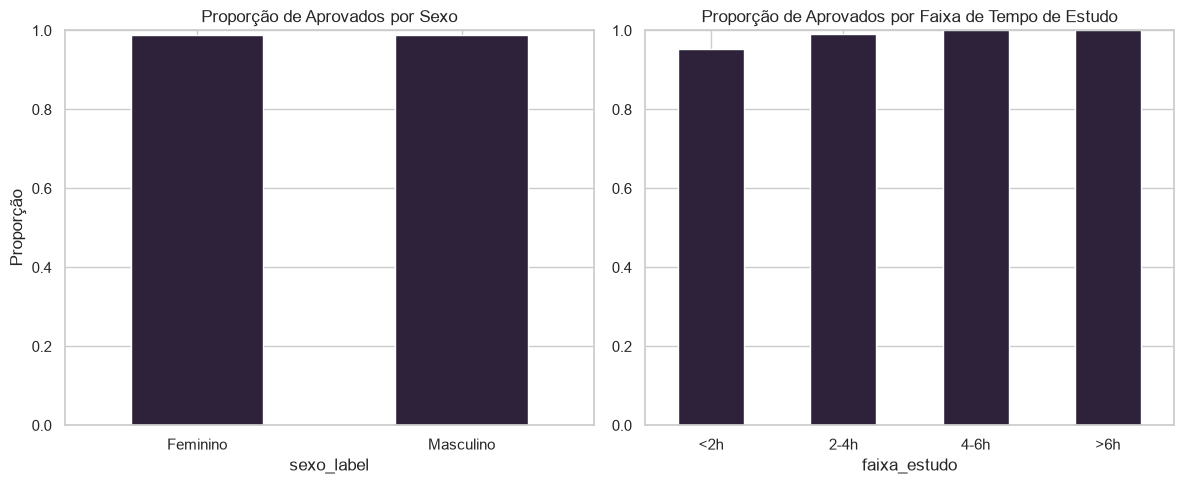

In [38]:
df["passed"] = df["final_exam_score"] >= 60

prop_por_sexo = pd.crosstab(df["sexo_label"], df["passed"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_estudo"], df["passed"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_sexo[True].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção de Aprovados por Sexo")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_faixa[True].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção de Aprovados por Faixa de Tempo de Estudo")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:**

Analisando os gráficos obtidos para o nosso dataset de desempenho estudantil:

1. **Por Sexo:** As proporções de aprovados para **Feminino** e **Masculino** podem ser comparadas diretamente no gráfico. O teste de Qui-Quadrado para sexo apresentou $p = 0{,}9014$, portanto não há evidência estatística de associação entre sexo e aprovação nesta amostra.
2. **Por Faixa de Tempo de Estudo:** O gráfico permite comparar a proporção de aprovados dentro de cada faixa. Como existem apenas 12 estudantes reprovados na base, pequenas diferenças entre as faixas devem ser interpretadas com cautela.

**Reflexão sobre Fairness e Contexto:**
* A análise de fairness permite identificar se o desfecho apresenta distribuições diferentes entre grupos definidos por determinados atributos.
* Um teste sem significância estatística não prova que os grupos sejam perfeitamente iguais nem elimina a possibilidade de viés; apenas indica que o teste não encontrou evidência suficiente de associação na amostra analisada.
* Diferenças observadas devem ser interpretadas considerando tamanho amostral, qualidade da coleta e outras variáveis que possam estar relacionadas ao desempenho.


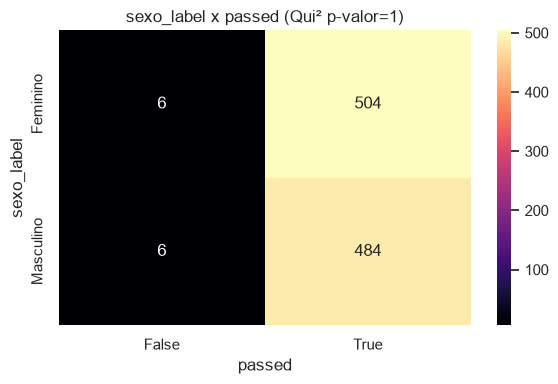

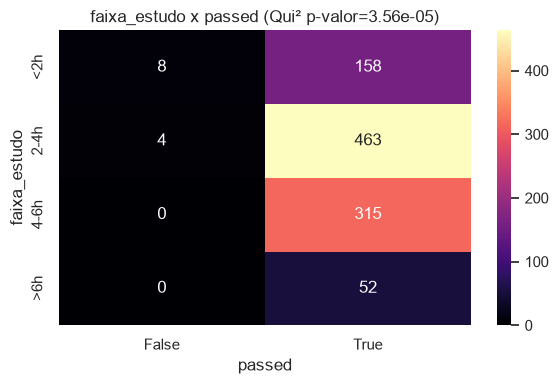

In [39]:
for atributo in ["sexo_label", "faixa_estudo"]:
    contingencia = pd.crosstab(df[atributo], df["passed"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x passed (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

**Pra discutir:**

Analisando o resultado do teste de Qui-Quadrado obtido para o nosso dataset de desempenho estudantil:

1. **Sexo vs. Aprovação:** O teste apresentou $p	ext{-valor} = 0{,}9014$. Como $p > 0{,}05$, não há evidência estatística suficiente para rejeitar a hipótese de independência entre sexo e `passed` nesta amostra.
2. **Faixa de Tempo de Estudo vs. Aprovação:** O segundo teste é calculado pelo código e seu p-valor aparece no título da matriz correspondente. A interpretação segue o mesmo critério: $p < 0{,}05$ indica evidência de associação; $p \ge 0{,}05$ indica que não há evidência suficiente para rejeitar a independência.

**Reflexão sobre Fairness e Interpretação:**
* O teste de Qui-Quadrado avalia associação entre variáveis categóricas, mas não demonstra causalidade.
* Um resultado não significativo não comprova ausência de viés; ele apenas indica que não foi encontrada evidência estatística suficiente para associação no teste realizado.
* Como há somente 12 reprovados, os resultados envolvendo `passed` devem ser interpretados com cautela.


#### Outliers bivariados

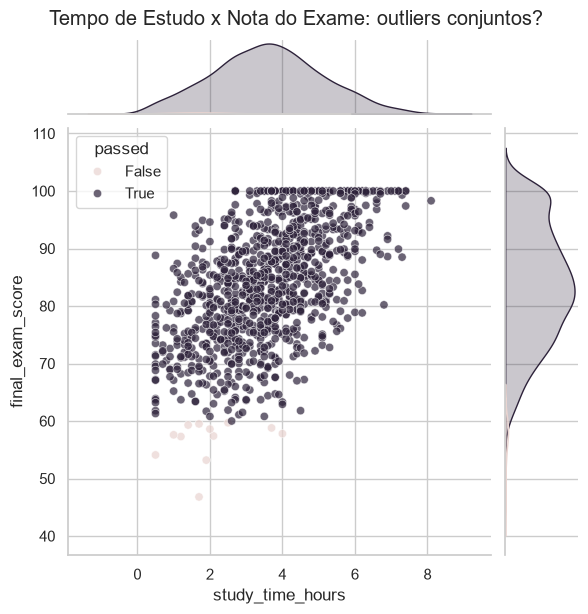

In [40]:
sns.jointplot(
    data=df,
    x="study_time_hours",
    y="final_exam_score",
    hue="passed",
    palette={False: COR_CONTEXTO, True: COR_DESTAQUE},
    alpha=0.7,
    height=6,
)
plt.suptitle("Tempo de Estudo x Nota do Exame: outliers conjuntos?", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `study_time_hours` e `final_exam_score`?

#### Análise Multivariada

##### Matriz de Correlação

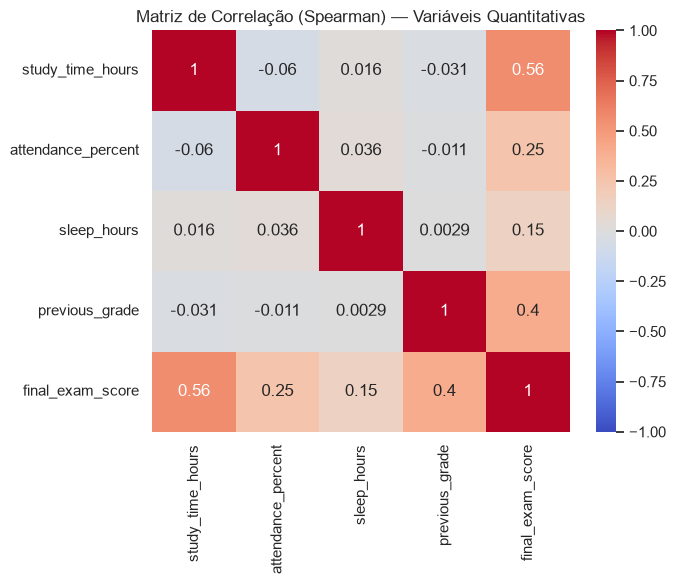

In [41]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()


**Análise das Correlações:**

* **`study_time_hours` x `final_exam_score` ($r = 0{,}56$):** Correlação **moderada** positiva. Indica uma associação monotônica positiva: estudantes com maior tempo de estudo tendem, nesta base, a apresentar notas finais maiores.
* **`previous_grade` x `final_exam_score` ($r = 0{,}40$):** Correlação **moderada** positiva. O histórico escolar prévio também apresenta associação com a nota final.
* **`attendance_percent` x `final_exam_score` ($r = 0{,}25$):** Correlação **fraca** positiva.
* **`sleep_hours` x `final_exam_score` ($r = 0{,}15$):** Correlação **fraca** positiva.
* **Demais pares de variáveis preditoras:** Todas as correlações entre as variáveis explicativas entre si (como horas de estudo vs. nota anterior ou presença vs. sono) possuem valores próximos de zero ($|r| < 0{,}06$), sendo **extremamente fracas/inexistentes**.

---

**Redundância entre Variáveis:**

**Não.** Nenhuma correlação atinge o limite de $|r| > 0{,}7$ para sugerir redundância ou multicolinearidade.

As correlações baixas entre as variáveis explicativas sugerem pouca redundância linear entre elas. Isso não é suficiente, por si só, para afirmar independência estatística completa ou garantir o desempenho de um modelo.

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão × Correlação')

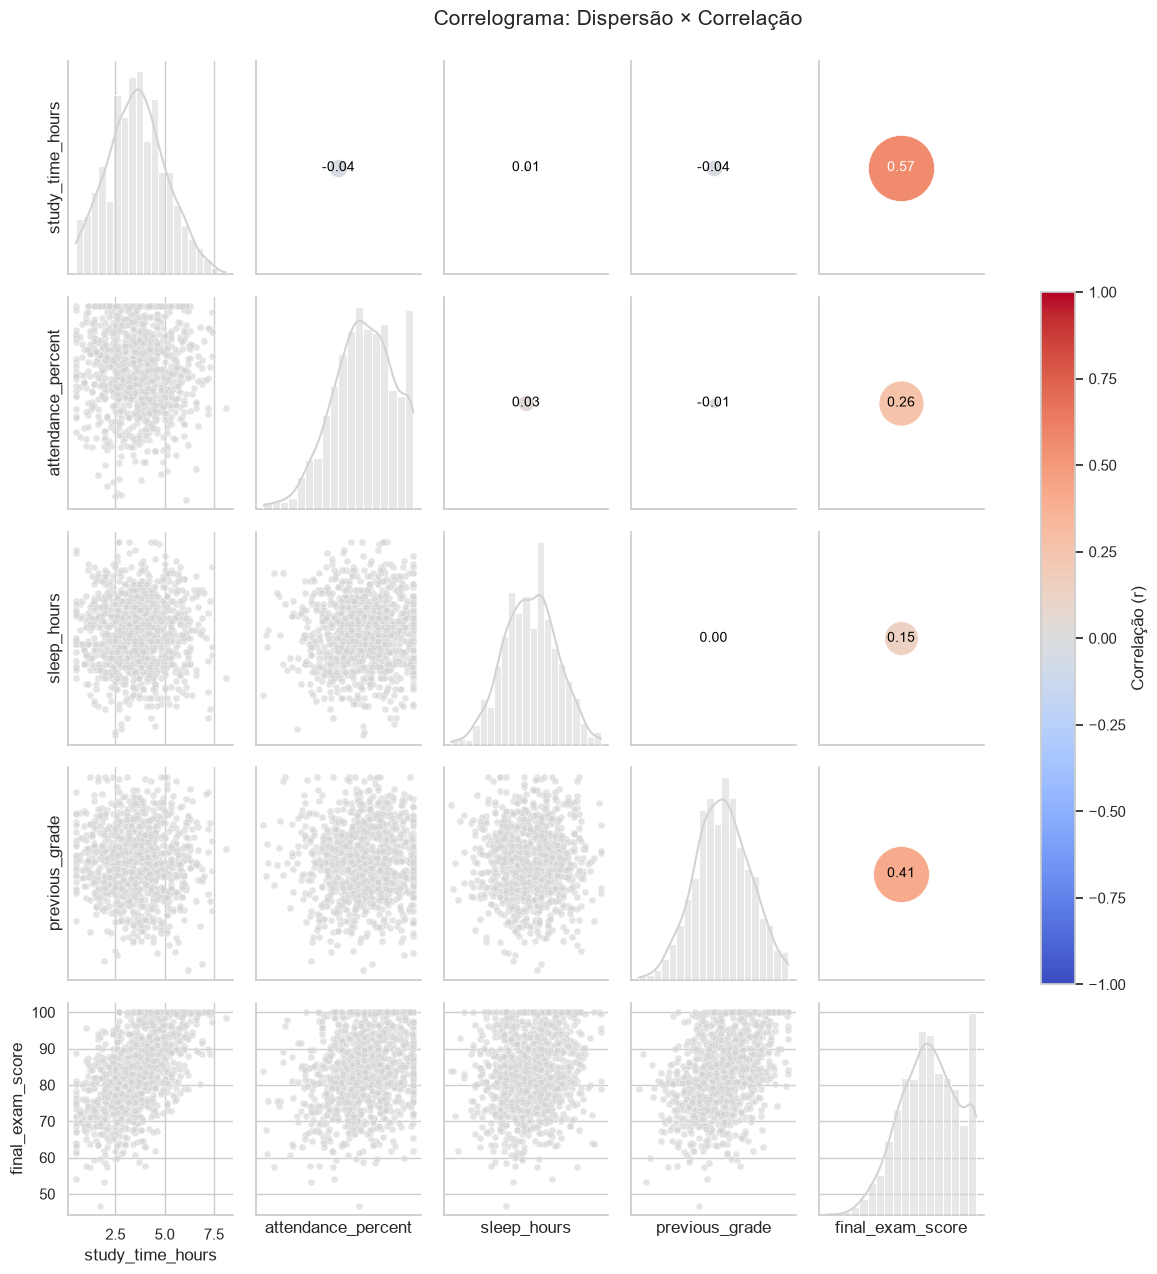

In [42]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_QUANT], diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)


### 1. Principais Conclusões

1. **Relação com o Desempenho:** O tempo de estudo (`study_time_hours`) apresentou a maior correlação positiva com a nota final (`final_exam_score`, $r = 0{,}56$), indicando uma associação moderada entre as duas variáveis.
2. **Histórico Escolar:** A nota prévia (`previous_grade`) também apresentou correlação moderada com a nota final ($r = 0{,}40$), indicando associação entre o desempenho anterior e o resultado do exame.
3. **Fairness:** O teste de Qui-Quadrado entre sexo e aprovação apresentou $p = 0{,}9014$, não fornecendo evidência estatística de associação entre essas variáveis na amostra analisada. Como o grupo de reprovados possui apenas 12 estudantes, as comparações por aprovação devem ser interpretadas com cautela.
4. **Redundância Linear:** Nenhuma das variáveis quantitativas explicativas apresentou correlação forte com outra variável explicativa ($|r| > 0{,}70$). Isso sugere baixa redundância linear entre elas, mas não permite afirmar independência estatística completa.

### 2. Declaração de Uso de IA

* **Ferramenta Utilizada:** ChatGPT.
* **Para o que foi aplicada:**
  1. Adaptação dos códigos de exemplo da aula para a estrutura e os nomes de colunas do dataset *Student Performance and Study Habits*.
  2. Correção de erros de execução e de referências a colunas que não existem no dataset.
  3. Suporte na estruturação e revisão dos textos explicativos e das reflexões de EDA e *Fairness*.
* **O que foi aceito/modificado/rejeitado e por quê:**
  * **Aceito:** A lógica de adaptação dos gráficos, os testes estatísticos e as análises de correlação aplicados às variáveis do dataset.
  * **Modificado:** A análise de grupos foi adaptada para sexo e faixas de tempo de estudo, pois o dataset não possui informação de idade.
  * **Rejeitado:** Referências a variáveis de outros datasets, como `chol`, `thal` e `trestbps`, pois elas não fazem parte do dataset utilizado nesta atividade.


In [43]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [44]:
# 🆕 NOVA CÉLULA — dataset ORIGINAL (reconstruído a partir do objeto `heart`, que não foi alterado)
path = kagglehub.dataset_download("harshadapatil31/student-performance-and-study-habits-dataset")

df_raw = pd.read_csv(os.path.join(path, 'student_performance_dataset.csv'))
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'dataset.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")

Raw salvo em ..\data\raw\dataset.csv — 1000 linhas x 12 colunas


In [ ]:
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")

Clean salvo em ..\data\clean\dataset.csv — 1000 linhas x 16 colunas
Linhas removidas no tratamento: 0


: 